# Лабораторна робота №5. Власне донавчання моделі
## Класифікація звернень клієнтів меблевої майстерні

**Студент:** Тімков Іван  
**Група:** ІПЗк-24-1  
**Метод:** класичне донавчання encoder-моделі з новою класифікаційною головою.

У цьому проєкті створюється класифікатор українськомовних звернень щодо корпусних меблів. Модель визначає категорію звернення. Експеримент виконується на `distilbert-base-multilingual-cased` — компактній багатомовній encoder-моделі. Її донавчання з новою класифікаційною головою добре підходить для безкоштовного Google Colab із GPU T4.

## 1.1. Задача

Користувачем системи є менеджер меблевої майстерні або онлайн-планувальника. Він отримує багато коротких повідомлень від клієнтів і має швидко визначити, до якого типу належить кожне звернення.

**Вхід:** текст українською мовою, наприклад: «Зменшіть глибину шафи до 500 мм».

**Вихід:** одна категорія з фіксованого переліку:
- `dimensions` — розміри виробу;
- `facade_material` — фасади, матеріали та декори;
- `configuration` — конструкція та конфігурація;
- `shelves_drawers` — полиці, шухляди й внутрішнє наповнення;
- `price` — вартість і кошторис;
- `delivery` — доставка та статус замовлення;
- `other` — інші питання.

Результат може використовуватися для автоматичного сортування звернень і передачі їх відповідальному менеджеру.

Звичайний промпт може класифікувати окремі повідомлення, але не гарантує стабільного використання саме внутрішнього переліку категорій і меж між близькими класами. RAG тут не є основним рішенням, оскільки класифікація не потребує пошуку в зовнішніх документах. Тому обрано донавчання класифікатора на прикладах предметної області. Це дозволяє адаптувати модель до спеціалізованих формулювань.

## 1.2. Модель і дані

**Модель:** `distilbert-base-multilingual-cased`.

Це багатомовна encoder-модель приблизно на 135 млн параметрів, яка підтримує український текст. Використовується саме базова модель, а не Instruct-LLM: задача є класифікацією з одним класом на виході, тому генерація довільного тексту не потрібна. До моделі додається класифікаційна голова на 7 класів, після чого вся модель донавчається.

**Дані:** власноруч підготовлений навчальний набір синтетичних прикладів. Він створений спеціально для цієї лабораторної, не скопійований із зовнішнього датасету. Ліцензія на створений набір — CC BY 4.0. У реальному проєкті синтетичні приклади потрібно доповнити перевіреними анонімізованими зверненнями клієнтів.

Дані зберігаються у форматі CSV з двома полями: `text` і `label`. Після формування набір поділяється на train, validation і test у пропорції 70/15/15 зі стратифікацією за класами. Тестова частина не використовується під час навчання чи вибору гіперпараметрів.

In [2]:
!pip -q install "transformers>=4.40,<5" datasets accelerate scikit-learn pandas matplotlib seaborn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [3]:
import os, random, time, json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from datasets import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding, set_seed
)

SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU."
device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)

GPU: Tesla T4
PyTorch: 2.14.1+cu130


### Формування датасету

Нижче наведено 15 різних формулювань для кожної з 7 категорій.

In [4]:
examples = {
"dimensions": [
"Зробіть шафу шириною 1800 мм і висотою 2400 мм.",
"Потрібно зменшити глибину корпусу до 500 міліметрів.",
"Змініть висоту шафи на 220 сантиметрів.",
"Чи можна збільшити ширину тумби на 15 сантиметрів?",
"Вкажіть точні габарити готової конструкції.",
"Мені потрібна шафа висотою не більше двох метрів.",
"Зробіть нижню секцію трохи ширшою.",
"Перерахуй проєкт із глибиною 600 мм.",
"Чи можна змінити товщину бокової стінки?",
"Зменште ширину дверцят відповідно до нового розміру.",
"Потрібно підігнати шафу під нішу 2100 на 900 мм.",
"Змініть загальну висоту виробу.",
"Зробіть корпус вужчим, бо мало місця.",
"Яка буде глибина шафи після зміни параметрів?",
"Потрібно скоригувати довжину та ширину виробу."
],
"facade_material": [
"Хочу фасади білого матового кольору.",
"Замініть фасад на акриловий.",
"Який декор доступний для дверцят?",
"Потрібен матеріал під натуральний дуб.",
"Зробіть фасади кольору графіт.",
"Чи є у вас глянцеві фасади?",
"Виберіть декор біла ніч для передніх панелей.",
"Змініть покриття фасадів на деревну текстуру.",
"Яка товщина матеріалу фасаду?",
"Покажіть доступні кольори ЛДСП.",
"Потрібні фасади з текстурою горіха.",
"Замість білого використайте сірий декор.",
"Хочу матове покриття без блиску.",
"Чи можна встановити акрилові дверцята?",
"Підберіть матеріал для фасадної частини."
],
"configuration": [
"Зробіть шафу кутовою замість прямої.",
"Додайте окрему секцію зліва.",
"Переробіть конструкцію на шафу купе з трьома дверима.",
"Потрібно змінити розташування секцій.",
"Додайте антресольний модуль зверху.",
"Зробіть двостулкову конструкцію.",
"Поміняйте місцями ліву та праву секції.",
"Хочу відкриту секцію збоку шафи.",
"Змініть тип дверей на розсувні.",
"Зробіть конструкцію з двома окремими модулями.",
"Потрібно додати бокову надбудову.",
"Переробіть шафу на вбудовану.",
"Змініть загальну схему корпусу.",
"Зробіть додаткову секцію для одягу.",
"Потрібна інша конфігурація модулів."
],
"shelves_drawers": [
"Додайте всередину три полиці.",
"Потрібні висувні шухляди в нижній секції.",
"Зробіть більше полиць для взуття.",
"Чи можна встановити кошики замість полиць?",
"Додайте одну довгу полицю посередині.",
"Зробіть два висувні ящики.",
"Потрібна штанга для вішаків і полиця над нею.",
"Змініть кількість внутрішніх полиць.",
"Додайте відділення для білизни з шухлядами.",
"Зробіть полиці з регульованою висотою.",
"Приберіть одну шухляду з нижньої частини.",
"Додайте внутрішній органайзер.",
"Потрібні висувні корзини для речей.",
"Зробіть окрему полицю для взуття.",
"Змініть внутрішнє наповнення шафи."
],
"price": [
"Скільки коштуватиме така шафа?",
"Потрібен попередній розрахунок вартості.",
"Чому ціна змінилася після вибору фасаду?",
"Надайте кошторис на виготовлення.",
"Яка загальна вартість замовлення?",
"Порахуйте ціну з новими розмірами.",
"Скільки коштуватимуть додаткові шухляди?",
"Чи можна отримати деталізацію ціни?",
"Потрібно зменшити бюджет проєкту.",
"Яка ціна одного фасаду?",
"Покажіть вартість матеріалів окремо.",
"Скільки буде коштувати монтаж?",
"Чи входить доставка у вказану суму?",
"Перерахуйте підсумкову вартість меблів.",
"Мені потрібна комерційна пропозиція."
],
"delivery": [
"Коли буде доставлено моє замовлення?",
"Замовлення затримується, потрібна інформація сьогодні.",
"Чи можлива доставка у суботу?",
"Я ще не отримав шафу, перевірте статус.",
"На яку дату заплановано привезення меблів?",
"Де зараз знаходиться моє замовлення?",
"Потрібно перенести дату доставки.",
"Коли очікувати монтаж після доставки?",
"Чи доставляєте ви меблі за місто?",
"Мені не повідомили час приїзду кур'єра.",
"Замовлення вже готове до відправлення?",
"Як відстежити доставку шафи?",
"Прошу уточнити термін виготовлення та доставки.",
"Чи можна змінити адресу доставки?",
"Меблі не привезли у погоджений день."
],
"other": [
"Доброго дня, хочу проконсультуватися.",
"Дякую за допомогу.",
"Як зв'язатися з менеджером?",
"Маю інше питання щодо замовлення.",
"Який у вас графік роботи?",
"Де знаходиться ваш салон?",
"Чи можна записатися на консультацію?",
"Надішліть, будь ласка, контактний номер.",
"Хочу дізнатися більше про вашу компанію.",
"Чи працюєте ви у вихідні?",
"Мені потрібна допомога з особистим кабінетом.",
"Як створити новий обліковий запис?",
"Де можна переглянути приклади робіт?",
"Підкажіть, як почати користуватися планувальником.",
"У мене загальне запитання до менеджера."
]
}

rows = [{"text": text, "label": label}
        for label, texts in examples.items() for text in texts]
df = pd.DataFrame(rows).sample(frac=1, random_state=SEED).reset_index(drop=True)
label_names = sorted(df["label"].unique())
label2id = {name:i for i,name in enumerate(label_names)}
id2label = {i:name for name,i in label2id.items()}
df["label_id"] = df["label"].map(label2id)

print("Кількість прикладів:", len(df))
print("Кількість класів:", len(label_names))
display(df.groupby("label").size().rename("examples").to_frame())
display(df.groupby("label").head(2)[["text","label"]])

Кількість прикладів: 105
Кількість класів: 7


,examples
label,
configuration,15
delivery,15
dimensions,15
facade_material,15
other,15
price,15
shelves_drawers,15


,text,label
0,Зробіть шафу кутовою замість прямої.,configuration
1,Порахуйте ціну з новими розмірами.,price
2,Яка загальна вартість замовлення?,price
3,Додайте відділення для білизни з шухлядами.,shelves_drawers
4,Додайте всередину три полиці.,shelves_drawers
5,Який у вас графік роботи?,other
6,У мене загальне запитання до менеджера.,other
8,Потрібно підігнати шафу під нішу 2100 на 900 мм.,dimensions
9,Зробіть шафу шириною 1800 мм і висотою 2400 мм.,dimensions
10,Потрібен матеріал під натуральний дуб.,facade_material


In [5]:
# Стратифікований поділ 70/15/15
train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=SEED, stratify=df["label"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["label"]
)
print(f"Train: {len(train_df)} ({len(train_df)/len(df):.1%})")
print(f"Validation: {len(val_df)} ({len(val_df)/len(df):.1%})")
print(f"Test: {len(test_df)} ({len(test_df)/len(df):.1%})")

# Перевірка: тексти не перетинаються між вибірками.
assert set(train_df.text).isdisjoint(set(val_df.text))
assert set(train_df.text).isdisjoint(set(test_df.text))
assert set(val_df.text).isdisjoint(set(test_df.text))

Train: 73 (69.5%)
Validation: 16 (15.2%)
Test: 16 (15.2%)


## 1.3. Модель до донавчання

Для класифікатора з новою головою використовується простий baseline: завжди передбачати найчастіший клас тренувальної вибірки. Це відповідає вимозі завдання щодо порівняння з найпростішим базовим рівнем.

Метрики:
- **Accuracy** — частка правильних класифікацій;
- **Macro-F1** — середнє F1 за всіма класами, тому кожна категорія має однакову вагу.

Додатково буде наведено 10 прикладів прогнозів після навчання, щоб було видно, як модель працює на окремих зверненнях.

In [6]:
majority_label = train_df["label"].value_counts().idxmax()
baseline_preds = [majority_label] * len(test_df)
baseline_accuracy = accuracy_score(test_df["label"], baseline_preds)
baseline_f1 = f1_score(test_df["label"], baseline_preds, average="macro", zero_division=0)
baseline = {"model":"Majority-class baseline", "accuracy":baseline_accuracy, "macro_f1":baseline_f1}
print("Baseline class:", majority_label)
print(baseline)

Baseline class: price
{'model': 'Majority-class baseline', 'accuracy': 0.125, 'macro_f1': 0.031746031746031744}


## 1.4. Донавчання

Використовується класичне донавчання `distilbert-base-multilingual-cased` з новою класифікаційною головою на 7 виходів.

Основні параметри:
- learning rate: `2e-5` — невеликий крок оновлення ваг попередньо навченої моделі;
- epochs: `4` — кілька проходів по невеликому навчальному набору;
- batch size: `8`;
- weight decay: `0.01` — регуляризація;
- evaluation: наприкінці кожної епохи на validation set.

Пікова пам'ять GPU та тривалість вимірюються безпосередньо під час запуску.

In [7]:
MODEL_NAME = "distilbert/distilbert-base-multilingual-cased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label_names),
    id2label=id2label,
    label2id=label2id
).to(device)

def tokenize_batch(batch):
    return tokenizer(batch["text"], truncation=True, max_length=128)

def make_dataset(frame):
    ds = Dataset.from_pandas(frame[["text","label_id"]].rename(columns={"label_id":"labels"}), preserve_index=False)
    return ds.map(tokenize_batch, batched=True)

train_ds = make_dataset(train_df)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)
collator = DataCollatorWithPadding(tokenizer=tokenizer)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro", zero_division=0)
    }

training_args = TrainingArguments(
    output_dir="furniture-intent-distilbert",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    num_train_epochs=4,
    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,

    metric_for_best_model="macro_f1",
    greater_is_better=True,

    logging_strategy="steps",
    logging_steps=2,

    fp16=True,
    report_to="none",
    seed=SEED
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    tokenizer=tokenizer,
    data_collator=collator,
    compute_metrics=compute_metrics
)

torch.cuda.reset_peak_memory_stats()
start_time = time.time()

train_output = trainer.train()

training_seconds = time.time() - start_time
peak_gpu_gb = torch.cuda.max_memory_allocated() / (1024**3)

print(f"Training time: {training_seconds/60:.2f} minutes")
print(f"Peak GPU memory: {peak_gpu_gb:.2f} GB")
print("Train metrics:", train_output.metrics)



/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/542M [00:00<?, ?B/s]

... (3 outputs left out)

Map:   0%|          | 0/16 [00:00<?, ? examples/s]

/tmp/ipykernel_2091/297012507.py:53: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.953900,1.925232,0.125000,0.033613
2,1.869900,1.900818,0.187500,0.105042
3,1.896300,1.866394,0.437500,0.311111
4,1.761800,1.851624,0.437500,0.319048


Training time: 0.97 minutes
Peak GPU memory: 2.04 GB
Train metrics: {'train_runtime': 57.5586, 'train_samples_per_second': 5.073, 'train_steps_per_second': 0.695, 'total_flos': 1473313719852.0, 'train_loss': 1.8909088134765626, 'epoch': 4.0}


### Графік training loss і validation loss

Trainer зберігає значення training loss під час навчання та validation loss наприкінці кожної епохи. Графік нижче використовує реальні записи `trainer.state.log_history`.

,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_macro_f1,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
13,1.8561,2.776763,8.500000e-06,2.4,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14,1.8626,3.034642,7.500000e-06,2.6,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15,1.8560,2.872797,6.500000e-06,2.8,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16,1.8963,7.750807,5.500000e-06,3.0,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17,NaN,NaN,NaN,3.0,30,1.866394,0.4375,0.311111,0.0525,305.039,19.065,NaN,NaN,NaN,NaN,NaN
18,1.8582,3.033547,4.500000e-06,3.2,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
19,1.8342,3.004828,3.500000e-06,3.4,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20,1.8401,2.803043,2.500000e-06,3.6,36,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21,1.8127,3.983339,1.500000e-06,3.8,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
22,1.7618,10.953159,5.000000e-07,4.0,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


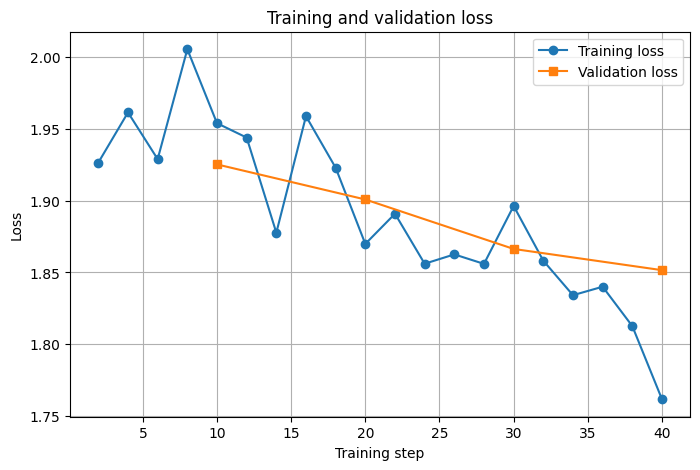

In [8]:
history = pd.DataFrame(trainer.state.log_history)
display(history.tail(12))

plt.figure(figsize=(8,5))
if "loss" in history.columns:
    train_points = history.dropna(subset=["loss"])
    plt.plot(train_points["step"], train_points["loss"], marker="o", label="Training loss")
if "eval_loss" in history.columns:
    val_points = history.dropna(subset=["eval_loss"])
    plt.plot(val_points["step"], val_points["eval_loss"], marker="s", label="Validation loss")
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("Training and validation loss")
plt.legend()
plt.grid(True)
plt.show()

## 1.5. Порівняння на тестовій вибірці

Після навчання модель оцінюється на тому самому тестовому наборі, який не використовувався для навчання. Результат порівнюється з majority-class baseline.

In [9]:
pred_output = trainer.predict(test_ds)
test_preds_ids = np.argmax(pred_output.predictions, axis=-1)
test_true_ids = test_df["label_id"].to_numpy()
test_preds = [id2label[int(i)] for i in test_preds_ids]

ft_accuracy = accuracy_score(test_true_ids, test_preds_ids)
ft_macro_f1 = f1_score(test_true_ids, test_preds_ids, average="macro", zero_division=0)

results = pd.DataFrame([
    {"model":"Majority-class baseline","accuracy":baseline_accuracy,"macro_f1":baseline_f1},
    {"model":"Fine-tuned DistilBERT","accuracy":ft_accuracy,"macro_f1":ft_macro_f1}
])
display(results)
print(classification_report(test_true_ids, test_preds_ids,
                            labels=list(range(len(label_names))),
                            target_names=label_names, zero_division=0))

,model,accuracy,macro_f1
0,Majority-class baseline,0.125,0.031746
1,Fine-tuned DistilBERT,0.375,0.294805


                 precision    recall  f1-score   support

  configuration       0.00      0.00      0.00         2
       delivery       0.00      0.00      0.00         2
     dimensions       1.00      0.33      0.50         3
facade_material       0.67      1.00      0.80         2
          other       0.00      0.00      0.00         3
          price       0.22      1.00      0.36         2
shelves_drawers       0.33      0.50      0.40         2

       accuracy                           0.38        16
      macro avg       0.32      0.40      0.29        16
   weighted avg       0.34      0.38      0.29        16



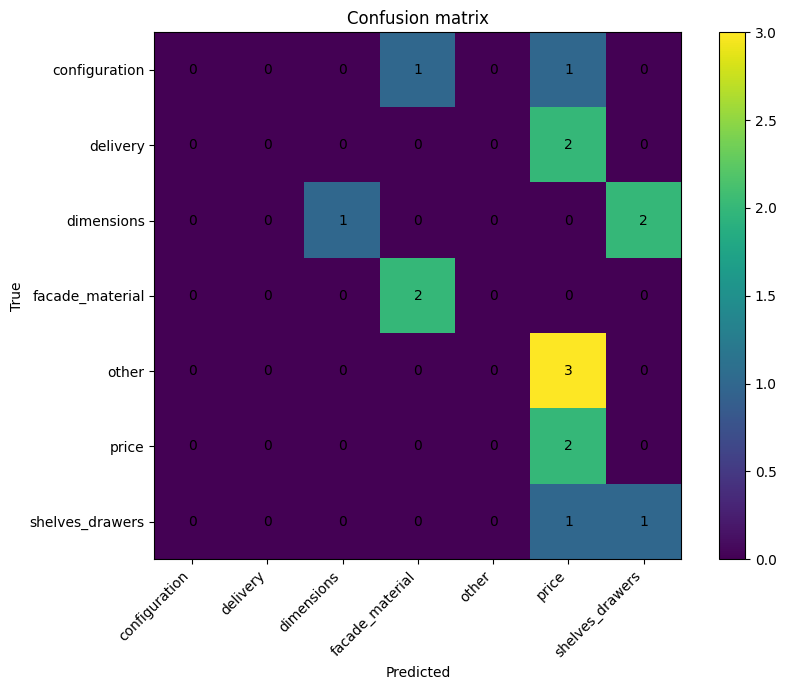

In [10]:
cm = confusion_matrix(test_true_ids, test_preds_ids, labels=list(range(len(label_names))))
plt.figure(figsize=(9,7))
plt.imshow(cm)
plt.xticks(range(len(label_names)), label_names, rotation=45, ha="right")
plt.yticks(range(len(label_names)), label_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion matrix")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i,j], ha="center", va="center")
plt.colorbar()
plt.tight_layout()
plt.show()

In [11]:
test_results = test_df[["text","label"]].copy()
test_results["prediction"] = test_preds
test_results["correct"] = test_results["label"] == test_results["prediction"]

print("10 прикладів прогнозів:")
display(test_results.head(10))

print("Помилки моделі:")
errors = test_results[~test_results["correct"]]
display(errors if len(errors) else pd.DataFrame({"message":["На цій тестовій вибірці помилок не виявлено."]}))

10 прикладів прогнозів:


,text,label,prediction,correct
39,Зробіть конструкцію з двома окремими модулями.,configuration,facade_material,False
101,Потрібно скоригувати довжину та ширину виробу.,dimensions,shelves_drawers,False
14,Чи можлива доставка у суботу?,delivery,price,False
38,Додайте внутрішній органайзер.,shelves_drawers,price,False
2,Яка загальна вартість замовлення?,price,price,True
86,Підберіть матеріал для фасадної частини.,facade_material,facade_material,True
61,Зробіть нижню секцію трохи ширшою.,dimensions,shelves_drawers,False
13,Чи можна записатися на консультацію?,other,price,False
104,Де можна переглянути приклади робіт?,other,price,False
20,Чи працюєте ви у вихідні?,other,price,False


Помилки моделі:


,text,label,prediction,correct
39,Зробіть конструкцію з двома окремими модулями.,configuration,facade_material,False
101,Потрібно скоригувати довжину та ширину виробу.,dimensions,shelves_drawers,False
14,Чи можлива доставка у суботу?,delivery,price,False
38,Додайте внутрішній органайзер.,shelves_drawers,price,False
61,Зробіть нижню секцію трохи ширшою.,dimensions,shelves_drawers,False
13,Чи можна записатися на консультацію?,other,price,False
104,Де можна переглянути приклади робіт?,other,price,False
20,Чи працюєте ви у вихідні?,other,price,False
84,Чи можна змінити адресу доставки?,delivery,price,False
27,Змініть загальну схему корпусу.,configuration,price,False


### Перевірка на загальних запитах поза предметною областю

Оскільки модель є вузьким класифікатором, а не універсальним чат-асистентом, загальні запити не повинні отримувати довільні відповіді. Перевіряємо, до якого класу модель примусово віднесе такі повідомлення. Це демонструє обмеження спеціалізованого класифікатора.

In [12]:
general_queries = [
    "Поясни, що таке штучний інтелект простими словами.",
    "Яка сьогодні погода у Києві?",
    "Напиши короткий вірш про осінь.",
    "Допоможи розв'язати квадратне рівняння.",
    "Як приготувати борщ?"
]
general_inputs = tokenizer(general_queries, return_tensors="pt", padding=True,
                            truncation=True, max_length=128).to(device)
model.eval()
with torch.no_grad():
    general_logits = model(**general_inputs).logits
general_preds = general_logits.argmax(dim=-1).cpu().tolist()
general_check = pd.DataFrame({
    "query":general_queries,
    "forced_category":[id2label[i] for i in general_preds]
})
display(general_check)

,query,forced_category
0,"Поясни, що таке штучний інтелект простими слов...",price
1,Яка сьогодні погода у Києві?,price
2,Напиши короткий вірш про осінь.,facade_material
3,Допоможи розв'язати квадратне рівняння.,price
4,Як приготувати борщ?,price


### Аналіз помилок

Помилки аналізуються за таблицею `errors` і матрицею невідповідностей. Категорії можуть плутатися, якщо формулювання одночасно містить кілька намірів, наприклад зміну конфігурації та додавання полиць. Модель також може помилятися на формулюваннях, яких немає у невеликому синтетичному датасеті.

Якщо помилок немає на тестовій вибірці, це не означає, що модель ідеальна: тестова вибірка мала й походить із того самого штучно сформованого набору. Потрібно перевірити її на нових реальних повідомленнях.

## Експорт результатів

Зберігаємо метрики, прогнози, історію навчання та саму модель.

In [13]:
results.to_csv("comparison_results.csv", index=False)
test_results.to_csv("test_predictions.csv", index=False)
history.to_csv("training_history.csv", index=False)
general_check.to_csv("general_queries_check.csv", index=False)
trainer.save_model("furniture-intent-distilbert-final")
tokenizer.save_pretrained("furniture-intent-distilbert-final")

print("Збережено:")
print("- comparison_results.csv")
print("- test_predictions.csv")
print("- training_history.csv")
print("- general_queries_check.csv")
print("- furniture-intent-distilbert-final/")

Збережено:
- comparison_results.csv
- test_predictions.csv
- training_history.csv
- general_queries_check.csv
- furniture-intent-distilbert-final/


## 1.6. Мій звіт


### Задача і чому потрібне донавчання
Реалізовано класифікатор українськомовних звернень клієнтів меблевої майстерні. На вхід подається текст повідомлення, на виході — одна з семи категорій: розміри, фасади й матеріали, конфігурація, полиці та шухляди, ціна, доставка або інше. Донавчання потрібне для адаптації моделі до спеціалізованого набору категорій і характерних формулювань предметної області. RAG не є необхідним, оскільки для визначення категорії не потрібно шукати інформацію у зовнішніх документах.

### Модель і дані
Використано `distilbert-base-multilingual-cased` — багатомовну encoder-модель, що підтримує українську мову. До неї додано класифікаційну голову на 7 класів. Датасет створено самостійно для лабораторної роботи; він містить 105 синтетичних прикладів (по 15 на кожну категорію), формат — CSV із полями `text` і `label`. Ліцензія власноруч створеного набору — CC BY 4.0. Поділ: train — 70%, validation — 15%, test — 15%; тестові приклади не використовувалися під час навчання.

### Метрика й результат до донавчання
Для порівняння використано baseline, який завжди повертає найчастіший клас тренувальної вибірки. Якість вимірюється за Accuracy та Macro-F1. Фактичні значення baseline наведені у таблиці `results` у ноутбуці.

### Метод донавчання й гіперпараметри
Застосовано класичне донавчання DistilBERT із новою класифікаційною головою. Learning rate — `2e-5`, кількість епох — 4, batch size — 8, weight decay — `0.01`, максимальна довжина послідовності — 128 токенів. Тривалість навчання та пікова пам'ять GPU виводяться після виконання `trainer.train()`. Графік training loss і validation loss побудовано за журналом Trainer.

### Результат після донавчання
Фактичні Accuracy та Macro-F1 донавченої моделі наведені у таблиці `results`. Порівняння виконується на тій самій тестовій вибірці, що й baseline. Після запуску потрібно вписати сюди числові значення та зазначити, чи перевищила донавчена модель baseline.

### Аналіз помилок
Помилкові приклади наведені в таблиці `errors`, а типи помилок можна побачити на матриці невідповідностей. Потенційними причинами є близькість окремих категорій, багатозначні повідомлення та малий обсяг синтетичного набору. Перевірка загальних запитів показує, що модель спеціалізована на класифікації звернень і не є універсальним чат-асистентом.

### Висновок
Під час роботи створено й донавчено класифікатор українськомовних звернень щодо корпусних меблів на базі DistilBERT. Було сформовано власний датасет, виконано поділ на train/validation/test, оцінено baseline, проведено донавчання та порівняно результати на незмінній тестовій вибірці. Ефективність донавчання оцінюється за Accuracy і Macro-F1. Обмеженням експерименту є невеликий синтетичний датасет; для практичного використання модель потрібно перевірити на більшій кількості реальних анонімізованих звернень.